# FRTB desk eligibility: the P&L attribution test and desk back-testing (C13)

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 03 of this topic (backtests and the traffic light)
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- state the two statistics of the profit-and-loss attribution (PLA) test, the Spearman correlation and the Kolmogorov-Smirnov distance, compute them by hand and obtain the engine's values and the committed ones;
- read the PLA zones and say why the engine decides the boundaries on integers;
- say what a desk-level back-test counts, what its limits are, and how a missing value is treated;
- read, for six planted deficiencies on a synthetic desk, which ones the PLA catches, which it misses and which statistic does the catching;
- give the 95 percent interval of a detection rate and say what a Monte Carlo share on known truth can and cannot claim.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import special, stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

# The engine's light values, in the words this notebook prints
LIGHT = {"green": "green", "amber": "amber", "red": "red", "not_evaluated": "not evaluated"}

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Case C13 asks what a validator concludes when a desk's risk model has a known deficiency. The data is **synthetic by design**: a generator produces the hypothetical P&L (HPL, from the exact revaluation of the desk) and the risk-theoretical P&L (RTPL, from the risk model) of a two-factor spread desk, and a deficiency is planted only in the risk model. Because the truth is known, each result is shown beside the deficiency it is meant to detect. This is not the book of any real desk and says nothing about any bank.

- `data/derived/C13/models-generator.json`: the generator, its parameters, the PLA thresholds and the desk limits.
- `data/derived/C13/<variant>.json` for six variants: `none` (no deficiency, the size of the test), `missing-basis`, `stale-volatility`, `wrong-correlation`, `omitted-factor` and `time-misalignment`. Each holds 1,000 replications of 250 days summarised (zones, detection counts, exception counts) and **one example replication** with its two P&L series of 250 days, the replication that has the median Spearman statistic.
- `data/derived/C11/fx-2008.json` supplies real data for the desk-level back-test of step 4.

The notebook recomputes the test on the six example replications and reads the summaries of the 1,000. The next cell loads the files and prints the planted deficiencies.

In [2]:
# Load the generator document and the six variants, and print the planted deficiency of each with its parameters
ROOT = Path("../../..").resolve()
VARIANTS = ("none", "missing-basis", "stale-volatility", "wrong-correlation", "omitted-factor", "time-misalignment")
c13 = {v: json.loads((ROOT / "data" / "derived" / "C13" / f"{v}.json").read_text(encoding="utf-8")) for v in VARIANTS}
generator = json.loads((ROOT / "data" / "derived" / "C13" / "models-generator.json").read_text(encoding="utf-8"))["fit"]
print("committed rows baked by riskvalidation", c13["none"]["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("truth status:", c13["none"]["provenance"]["truth_status"], "|", generator["generator"]["notice"]["en"][:60] + "...")
print("PLA thresholds:", {k: v for k, v in generator["pla_thresholds"].items() if k != "reference"}, "| desk limits:", {d["alpha"]: d["limit_exceptions"] for d in generator["desk_limits"]})
for v in VARIANTS:
    known = c13[v]["outputs"]["known_deficiency"]
    print(f"{v:18s} planted {known['planted']!s:5s} meant to fail: {known['intended_to_fail']:9s} parameters {[(p['name'], p['value']) for p in known['parameters']]}")

committed rows baked by riskvalidation 0.7.0 | installed 0.9.0
truth status: synthetic-known-truth | Synthetic data: this is generated desk P&L with a risk model...
PLA thresholds: {'spearman_green': 0.8, 'spearman_red': 0.7, 'ks_green': 0.09, 'ks_red': 0.12, 'ecdf_step': 0.004, 'window_days': 250} | desk limits: {0.025: 30, 0.01: 12}
none               planted False meant to fail: none      parameters []
missing-basis      planted True  meant to fail: spearman  parameters [('basis_sd_share', 0.65)]
stale-volatility   planted True  meant to fail: ks        parameters [('vol_lag_days', 20.0)]
wrong-correlation  planted True  meant to fail: either    parameters [('correlation_error', 0.3)]
omitted-factor     planted True  meant to fail: spearman  parameters [('omitted_loading_share', 0.6)]
time-misalignment  planted True  meant to fail: spearman  parameters [('lag_days', 1.0)]


## Method

### Step 1: the PLA test

The FRTB internal-models approach (Basel Framework MAR32.36 to MAR32.42) asks whether the risk model explains the desk's P&L. On the most recent 250 days it compares the risk-theoretical P&L with the hypothetical one in two ways. The **Spearman correlation** is the Pearson correlation of the ranks, so it asks whether the two series order the days alike:

$$r_S = \frac{\operatorname{cov}(R_{HPL}, R_{RTPL})}{\sigma_{R_{HPL}}\,\sigma_{R_{RTPL}}}$$

The **Kolmogorov-Smirnov** distance asks whether the two series have the same distribution, with the empirical distribution function $F(x) = 0.004\cdot\#\{\text{observations} \le x\}$:

$$KS = \sup_x \left| F_{RTPL}(x) - F_{HPL}(x) \right|$$

The zone is **green** if $r_S > 0.80$ and $KS < 0.09$, **red** if $r_S < 0.70$ or $KS > 0.12$, **amber** otherwise. Red makes the desk ineligible for the internal models approach; amber keeps it with a capital surcharge. The engine's `pla_spearman`, `pla_ks`, `pla_zone` and `pla_test` implement these. The cell computes both statistics by hand on the example replication of the `none` variant, with SciPy's rank correlation and a count of the steps of the two distribution functions, and compares them with the engine and the committed row.

In [3]:
# Spearman and Kolmogorov-Smirnov by hand on the example replication of the "none" variant, against the engine and the committed row
from riskvalidation.market.frtb import pla_ks, pla_spearman, pla_zone
from riskvalidation.validation.market import pla_test

example = c13["none"]["outputs"]["example"]
hpl, rtpl = np.array(example["hpl"]), np.array(example["rtpl"])
print(f"replication {example['replication_index']} (seed {example['seed']}): {hpl.size} days each | HPL standard deviation {hpl.std():.5f} | RTPL {rtpl.std():.5f}")

rho_by_hand = stats.spearmanr(hpl, rtpl).statistic
points = np.union1d(hpl, rtpl)
ecdf_hpl = np.searchsorted(np.sort(hpl), points, side="right") * 0.004
ecdf_rtpl = np.searchsorted(np.sort(rtpl), points, side="right") * 0.004
ks_by_hand = float(np.max(np.abs(ecdf_rtpl - ecdf_hpl)))
print(f"by hand: Spearman {rho_by_hand:.6f} | KS {ks_by_hand:.3f}")
print(f"engine : Spearman {pla_spearman(hpl, rtpl):.6f} | KS {pla_ks(hpl, rtpl):.3f} | zone {pla_zone(pla_spearman(hpl, rtpl), pla_ks(hpl, rtpl))}")

result = pla_test(hpl, rtpl, model_id="desk-risk-model")
row = [t for t in c13["none"]["tests"] if t["test_id"] == "market.pla_test"][0]
print(f"pla_test : statistic {result.statistic:.6f} | metric {result.metric:.3f} | light {LIGHT[result.light.value]}")
print(f"committed: statistic {row['statistic']:.6f} | metric {row['metric']:.3f} | light {LIGHT[row['light']]}")

replication 9 (seed 13009): 250 days each | HPL standard deviation 0.00529 | RTPL 0.00522
by hand: Spearman 0.992332 | KS 0.032
engine : Spearman 0.992332 | KS 0.032 | zone green
pla_test : statistic 0.992332 | metric 0.032 | light green
committed: statistic 0.992332 | metric 0.032 | light green


### Step 2: boundaries decided on integers

A zone boundary is a hard line, and a statistic that falls exactly on it must not be moved by floating-point rounding. The KS distance is an integer count of steps over 250, so $KS < 0.09$ is $\text{gap} \le 22$ and $KS > 0.12$ is $\text{gap} \ge 31$. The Spearman boundaries 0.80 and 0.70 are decided by `compare_spearman`, which works on the doubled average ranks as integers and compares $S_{xy}^2$ with $\text{threshold}^2\,S_{xx}S_{yy}$ in exact rational arithmetic, returning 1, 0 or -1 for above, on and below. `pla_zone_exact` uses both and agrees with the float rule `pla_zone` except where a float quotient would sit on a boundary. The cell prints, for the example replication of each variant, the step gap, the comparison with each Spearman boundary and the two zone rules.

In [4]:
# For each variant's example: the KS step gap, the exact comparison with each Spearman boundary, and the float and exact zone rules
from riskvalidation.market.frtb import compare_spearman, pla_zone_exact

print(f"{'variant':18s} {'Spearman':>9s} {'KS':>6s} {'gap':>4s} {'vs 0.80':>8s} {'vs 0.70':>8s}  {'float zone':10s} {'exact zone':10s}")
for v in VARIANTS:
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    rho, ks = pla_spearman(h, r), pla_ks(h, r)
    print(f"{v:18s} {rho:9.4f} {ks:6.3f} {round(ks * 250):4d} {compare_spearman(h, r, 0.80):8d} {compare_spearman(h, r, 0.70):8d}  "
          f"{LIGHT[pla_zone(rho, ks)]:10s} {LIGHT[pla_zone_exact(h, r)]:10s}")

variant             Spearman     KS  gap  vs 0.80  vs 0.70  float zone exact zone
none                  0.9923  0.032    8        1        1  green      green     
missing-basis         0.7107  0.104   26       -1        1  amber      amber     
stale-volatility      0.9793  0.044   11        1        1  green      green     
wrong-correlation     0.9865  0.144   36        1        1  red        red       
omitted-factor        0.7749  0.080   20       -1        1  amber      amber     
time-misalignment    -0.0065  0.028    7       -1       -1  red        red       


### Step 3: the six example replications against the committed rows

One replication is one draw, but it shows the mechanism: each deficiency leaves a different mark on the two statistics. The cell recomputes `pla_test` on the example of every variant and checks it against the committed `market.pla_test` row, and draws RTPL against HPL for each. A **missing basis** or an **omitted factor** adds P&L the model cannot see, which weakens the rank correlation; a **time misalignment** destroys the day-by-day match completely; a **wrong correlation** keeps the order of the days but changes the spread of the model's P&L, which the KS distance sees and the Spearman correlation does not; a **stale volatility** changes little of either.

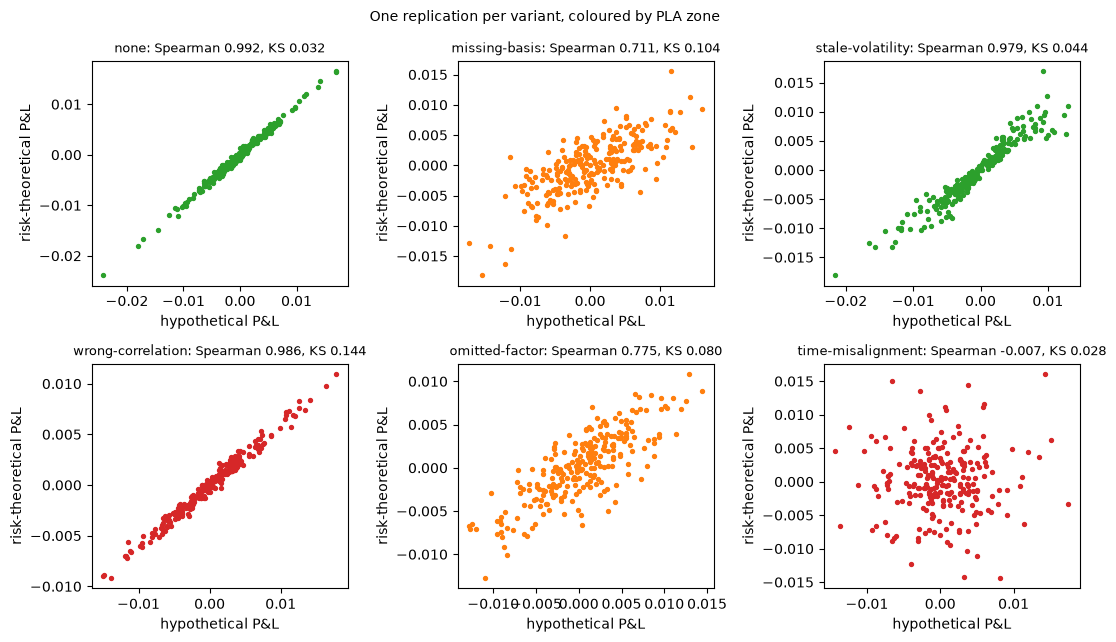

largest difference from the committed rows, six variants: 4.1e-10; every zone equal to the committed one


In [5]:
# Recompute pla_test on each variant's example and compare with the committed row, then draw RTPL against HPL
fig, axes = plt.subplots(2, 3, figsize=(11, 6.5))
colour = {"green": "tab:green", "amber": "tab:orange", "red": "tab:red"}
worst = 0.0
for ax, v in zip(axes.ravel(), VARIANTS):
    example = c13[v]["outputs"]["example"]
    h, r = np.array(example["hpl"]), np.array(example["rtpl"])
    fresh = pla_test(h, r, model_id="desk-risk-model")
    row = [t for t in c13[v]["tests"] if t["test_id"] == "market.pla_test"][0]
    worst = max(worst, abs(fresh.statistic - row["statistic"]), abs(fresh.metric - row["metric"]))
    assert fresh.light.value == row["light"]
    ax.scatter(h, r, s=8, color=colour[fresh.light.value])
    ax.set_title(f"{v}: Spearman {fresh.statistic:.3f}, KS {fresh.metric:.3f}", fontsize=9)
    ax.set_xlabel("hypothetical P&L")
    ax.set_ylabel("risk-theoretical P&L")
fig.suptitle("One replication per variant, coloured by PLA zone", fontsize=10)
fig.tight_layout()
plt.show()
print(f"largest difference from the committed rows, six variants: {worst:.1e}; every zone equal to the committed one")

### Step 4: the desk-level back-test

Besides the PLA test, an internal-models desk must back-test its VaR at the desk level (MAR32.18 to MAR32.19): over the most recent 250 days it counts the days on which the loss exceeded the desk's one-day VaR, and the desk **moves to the standardised approach** if the count exceeds 12 at 99 percent or 30 at 97.5 percent. The engine has `desk_exception_limit(alpha)`, `desk_exceptions(loss, var, missing_as_exception)` and `desk_backtest(loss, var, alpha, basis)`. A missing loss or VaR counts as an exception by default, since the framework treats a missing value as an outlier for the bank-wide test and the engine keeps the same rule for a desk behind a flag. There is no amber: the light is red above the limit and green otherwise.

The synthetic desks of C13 commit their exception counts but not the loss and VaR series, so this step uses real data: the euro position of `fx-2008` as a one-position desk, its realised loss and the committed `ewma` VaR for the last 250 of its 251 days. The cell shows the count, the limit and the light at both levels, then blanks two days to show the treatment of missing values.

In [6]:
# Desk back-test of the euro position (a one-position desk): exceptions in the last 250 days against the limit, and missing values
from riskvalidation.market.frtb import desk_exception_limit, desk_exceptions
from riskvalidation.validation.market import desk_backtest

fx = json.loads((ROOT / "data" / "derived" / "C11" / "fx-2008.json").read_text(encoding="utf-8"))
fx_loss = np.array(fx["outputs"]["grid"]["realised_loss"]["loss"])
ewma = {m["model_id"]: m for m in fx["outputs"]["models"]}["ewma"]
for level in ewma["by_level"]:
    alpha = level["alpha"]
    var = np.array(level["var"])
    outcome = desk_backtest(fx_loss, var, alpha, model_id="ewma", basis="HPL")
    print(f"alpha {alpha}: exceptions in the last 250 days {int(outcome.statistic)} | limit {int(outcome.metric)} | light {LIGHT[outcome.light.value]}")

alpha = 0.01
var = np.array(ewma["by_level"][0]["var"])
blanked = fx_loss.copy()
blanked[[100, 101]] = np.nan                                   # two days with no P&L
print("limits:", {a: desk_exception_limit(a) for a in (0.01, 0.025)})
print(f"missing counted as exceptions: {desk_exceptions(blanked[-250:], var[-250:])} | missing ignored: "
      f"{desk_exceptions(blanked[-250:], var[-250:], missing_as_exception=False)} | no missing values: {desk_exceptions(fx_loss[-250:], var[-250:])}")

alpha 0.01: exceptions in the last 250 days 3 | limit 12 | light green
alpha 0.025: exceptions in the last 250 days 8 | limit 30 | light green
limits: {0.01: 12, 0.025: 30}
missing counted as exceptions: 5 | missing ignored: 3 | no missing values: 3


### Step 5: how often each deficiency is caught

What a validator needs to know is not whether the test caught one replication but how **often**. Each variant ran 1,000 replications, and the artifact records how many were amber or red on the PLA (the deficiency is **caught**), how many were red, how many exceeded the desk limit at 99 percent, and which statistic flagged them. For the variant with no deficiency the same share is the **false-alarm rate** (the size of the test). A share $\hat p$ from $n$ replications carries Monte Carlo error: the standard error is $\sqrt{\hat p(1-\hat p)/n}$, which is zero at 0 and 1, so the artifact reports the Wilson score interval, which stays inside [0, 1] and is not degenerate at the edges (Brown, Cai and DasGupta, 2001). The cell reads the shares, recomputes the interval by hand and compares it with the committed one.

In [7]:
# Detection shares of the 1,000 replications per variant, with the Wilson interval recomputed by hand against the committed one
z = 1.96
print(f"{'variant':18s} {'caught':>7s} {'red':>6s} {'desk>12':>8s} {'Spearman':>9s} {'KS':>5s} {'interval (hand)':>20s} {'(committed)':>20s}")
interval_gap = 0.0
for v in VARIANTS:
    out = c13[v]["outputs"]
    det = out["detection"]
    n, k = det["n_replications"], det["n_amber_or_red"]
    p = k / n
    centre = (p + z ** 2 / (2 * n)) / (1 + z ** 2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / (1 + z ** 2 / n)
    interval_gap = max(interval_gap, abs(centre - half - det["ci_low"]), abs(centre + half - det["ci_high"]))
    by = det["by_test"]
    print(f"{v:18s} {p:7.3f} {det['share_red']:6.3f} {c13[v]['impact']['share_desk_over_limit_99']['value']:8.3f} {by['spearman_flagged']:9d} {by['ks_flagged']:5d} "
          f"{centre - half:9.4f} to {centre + half:7.4f} {det['ci_low']:9.4f} to {det['ci_high']:7.4f}")
print(f"largest difference between the hand interval and the committed one: {interval_gap:.1e}")

variant             caught    red  desk>12  Spearman    KS      interval (hand)          (committed)
none                 0.000  0.000    0.000         0     0    0.0000 to  0.0038    0.0000 to  0.0038
missing-basis        0.960  0.575    0.565       919   867    0.9460 to  0.9705    0.9460 to  0.9705
stale-volatility     0.000  0.000    0.005         0     0    0.0000 to  0.0038    0.0000 to  0.0038
wrong-correlation    1.000  0.913    0.953         0  1000    0.9962 to  1.0000    0.9962 to  1.0000
omitted-factor       0.901  0.043    0.064       805   448    0.8809 to  0.9180    0.8809 to  0.9180
time-misalignment    1.000  1.000    0.000      1000     0    0.9962 to  1.0000    0.9962 to  1.0000
largest difference between the hand interval and the committed one: 4.3e-10


The last figure draws the detection shares: for each variant the share of replications caught by the PLA (amber or red), the share red, and the share over the desk limit at 99 percent, with the Wilson interval on the first. The variant with no deficiency shows the false-alarm rate; the others show the power against a deficiency of the stated size.

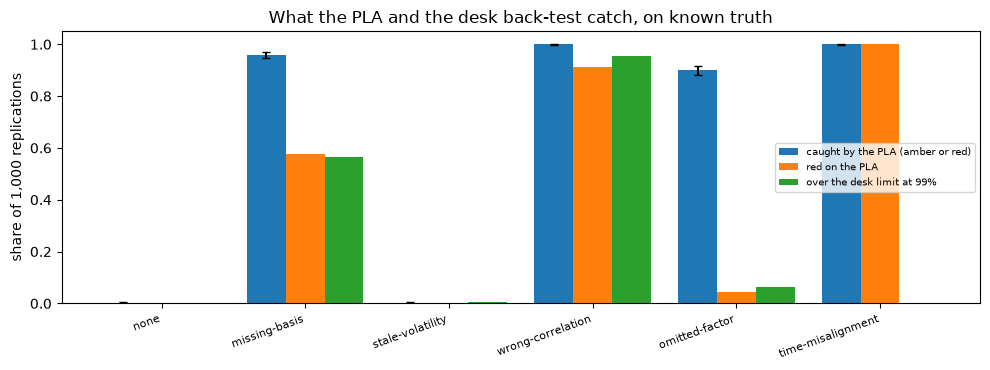

In [8]:
# Draw the share caught, the share red and the share over the 99% desk limit for each variant, with the committed interval
fig, ax = plt.subplots(figsize=(10, 3.8))
width = 0.27
positions = np.arange(len(VARIANTS))
caught = np.array([c13[v]["outputs"]["detection"]["share_amber_or_red"] for v in VARIANTS])
low = np.array([c13[v]["outputs"]["detection"]["ci_low"] for v in VARIANTS])
high = np.array([c13[v]["outputs"]["detection"]["ci_high"] for v in VARIANTS])
red = np.array([c13[v]["impact"]["share_red"]["value"] for v in VARIANTS])
desk = np.array([c13[v]["impact"]["share_desk_over_limit_99"]["value"] for v in VARIANTS])
ax.bar(positions - width, caught, width, yerr=[caught - low, high - caught], capsize=3, label="caught by the PLA (amber or red)")
ax.bar(positions, red, width, label="red on the PLA")
ax.bar(positions + width, desk, width, label="over the desk limit at 99%")
ax.set_xticks(positions)
ax.set_xticklabels(VARIANTS, rotation=20, ha="right", fontsize=8)
ax.set_ylabel("share of 1,000 replications")
ax.set_title("What the PLA and the desk back-test catch, on known truth")
ax.legend(fontsize=7)
fig.tight_layout()
plt.show()

## Results

- **The statistics by hand.** On the example replication of the `none` variant (replication 9, seed 13009) the Spearman correlation is 0.992332 and the KS distance 0.032 (a gap of 8 steps of 250) by hand, by the engine and in the committed row, and the zone is green. For the six examples the largest difference from the committed `pla_test` rows is 4.1e-10 and every zone is the committed one.
- **Boundaries on integers.** `missing-basis` (Spearman 0.7107, gap 26) and `omitted-factor` (0.7749, gap 20) are amber because their Spearman lies between 0.70 and 0.80 (comparison -1 against 0.80, +1 against 0.70). `wrong-correlation` has a Spearman of 0.9865 and a gap of 36, past the red limit of 31, so it is red on KS alone. `time-misalignment` has a Spearman of -0.0065 and is red. The float rule and the exact rule agree on all six.
- **The desk back-test.** Treating the euro position of `fx-2008` as a one-position desk, the `ewma` VaR has 3 exceptions in the last 250 days at 99 percent (limit 12) and 8 at 97.5 percent (limit 30): green at both. With two days of missing P&L the count is 5 when missing values count as exceptions, the default, and 3 when they are ignored.
- **False alarms.** With no deficiency the PLA is amber or red in 0 of 1,000 replications, and the 95 percent interval of that share ends at 0.0038: the test almost never accuses a correct model on this generator.
- **What is caught.** `time-misalignment` is caught in 100 percent of replications (all red, all by Spearman), `wrong-correlation` in 100 percent (91.3 percent red, all by KS, none by Spearman), `missing-basis` in 96.0 percent (interval 0.946 to 0.970; 57.5 percent red; Spearman flags 919 and KS 867) and `omitted-factor` in 90.1 percent (0.881 to 0.918; only 4.3 percent red). `stale-volatility`, a 20-day lag in the volatility input, is caught in **0** of 1,000 replications (upper limit 0.0038): the PLA, which the file marks as meant to fail on KS, does not see it.
- **The desk back-test catches a different subset.** It exceeds its 99 percent limit in 95.3 percent of the `wrong-correlation` replications, 56.5 percent of `missing-basis`, 6.4 percent of `omitted-factor`, 0.5 percent of `stale-volatility` and none of `time-misalignment`, which the PLA catches every time. Neither test dominates the other.
- **The interval.** The Wilson interval recomputed by hand matches the committed one to 4.3e-10. It is the interval of a Monte Carlo share on a generator with known truth; it says nothing about how often a real desk has one of these deficiencies.

What this notebook does not show: the capital consequences of an amber or red desk (surcharge or standardised approach), which belong to the regulatory calculators.

## Summary

- The PLA test has two statistics that see different things: the Spearman correlation sees whether the two P&L series order the days alike, the KS distance whether they have the same distribution. A deficiency can break one and leave the other intact, so the joint zone takes the worse of the two.
- Zone boundaries are decided on integers (a step gap for KS, exact rational arithmetic for Spearman), so a value on a boundary is never moved by rounding.
- The desk back-test counts exceptions against a limit (12 at 99 percent, 30 at 97.5 percent) with no amber, and a missing value counts as an exception by default.
- On a synthetic desk with a planted deficiency the truth is known, so the test can be judged by its detection rate and its false-alarm rate, each with an interval. The PLA catches some deficiencies almost always and others never, and the desk back-test catches a different subset.
- A Monte Carlo share on known truth says how the test behaves on these generators; it does not say how often a real desk has these deficiencies.

**What to try next.** For one variant, take the example's `rtpl` and shift it by one day with `np.roll`, recompute the zone, and compare with the `time-misalignment` variant; then read the SDD's description of the generator.

## References

- Basel Committee on Banking Supervision, Basel Framework, MAR32.18 to MAR32.19 (desk-level back-testing) and MAR32.36 to MAR32.42 (the profit and loss attribution test), as implemented by the engine's `riskvalidation.market.frtb`.
- Basel Committee on Banking Supervision (1996), Supervisory framework for the use of backtesting in conjunction with the internal models approach to market risk capital requirements. https://www.bis.org/publ/bcbs22.htm
- Brown, L. D., Cai, T. T. and DasGupta, A. (2001), Interval estimation for a binomial proportion, Statistical Science 16(2). https://doi.org/10.1214/ss/1009213286